# Proyecto Final Integrador
## Predicción de abandono (churn) de clientes en una empresa de telecomunicaciones

**Diplomado en Ciencia de Datos y Análisis Avanzado - UTN.BA - Unidad 10**

**Grupo 4** - Integrantes: Agustín Bilche Braga, Agustina Díaz, Carlos Grozo, Milagros Crespo, Luana Zalcman.

Este notebook reproduce **todos** los números del informe final y guarda tablas y figuras en `results/`. Sigue CRISP-DM:

1. Comprensión del negocio: KPI y métricas
2. Comprensión de los datos (calidad y EDA)
3. Preparación de los datos
4. Modelado: baseline, Random Forest y Gradient Boosting con validación cruzada
5. Evaluación en el test (una sola vez)
6. Interpretación (SHAP) y prueba de quitar variables
7. Auditoría por grupos (ética)
8. Traducción a negocio
9. Predicciones sobre `test.csv`

**Cambios respecto de la pre-entrega (devolución del tutor):**
- Se habla de **tasa de churn observada en la muestra**, no de "tasa mensual": el dataset es una foto estática sin dimensión temporal.
- El baseline (Regresión Logística) se compara con **Random Forest** y **Gradient Boosting**; no se agregan modelos de relleno.
- Se incorpora **PR-AUC** junto a Recall y ROC-AUC.
- El resultado se traduce a negocio: **si se contacta al 20 % de clientes con mayor riesgo, qué porcentaje de los que abandonan se detecta**.
- **SMOTE se aplica solo sobre datos de entrenamiento**, dentro del pipeline de cada fold.

## 0. Configuración

[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/jgrozo660/Proyecto-Final-AnalisisDeDatos-UTN/blob/main/proyecto_integrador.ipynb)

La primera celda prepara el entorno: si el notebook se abre en **Google Colab** (o en cualquier carpeta sin los datos), clona el repositorio público para disponer de `data/train.csv` y `data/test.csv`, e instala las librerías que falten. En una copia local del repositorio no hace nada.

In [1]:
import os, sys, subprocess, warnings
warnings.filterwarnings("ignore")
REPO = "https://github.com/jgrozo660/Proyecto-Final-AnalisisDeDatos-UTN"
if not os.path.exists(os.path.join("data", "train.csv")):
    carpeta = REPO.rsplit("/", 1)[-1]
    if not os.path.exists(carpeta):
        subprocess.run(["git", "clone", "-q", "--depth", "1", REPO], check=True)
    os.chdir(carpeta)
for paquete, modulo in [("imbalanced-learn", "imblearn"), ("shap", "shap")]:
    try:
        __import__(modulo)
    except ImportError:
        subprocess.run([sys.executable, "-m", "pip", "install", "-q", paquete], check=True)
print("Directorio de trabajo:", os.path.basename(os.getcwd()))

Directorio de trabajo: proyecto-final-analisisdedatos-utn


In [2]:
import os, math, warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split, StratifiedKFold
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from sklearn.base import clone
from sklearn.metrics import (average_precision_score, roc_auc_score, precision_recall_curve,
                             recall_score, precision_score, f1_score, accuracy_score,
                             confusion_matrix)
from sklearn.calibration import calibration_curve
from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import SMOTE
import shap

warnings.filterwarnings("ignore")
SEED = 42
CUPO = 0.20          # fracción de la cartera que el área de retención puede contactar
DATA_DIR = "data"
RES = "results"
os.makedirs(RES, exist_ok=True)

# Estilo de figuras (impresión, fondo claro)
AZUL, NARANJA, AQUA, GRIS = "#2a78d6", "#eb6834", "#1baf7a", "#9a9993"
TINTA, TINTA2 = "#0b0b0b", "#52514e"
plt.rcParams.update({
    "figure.dpi": 110, "savefig.dpi": 200, "font.size": 10, "axes.titlesize": 11,
    "axes.edgecolor": "#c9c8c2", "axes.labelcolor": TINTA2, "xtick.color": TINTA2, "ytick.color": TINTA2,
    "axes.grid": True, "grid.color": "#ebeae6", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.spines.top": False, "axes.spines.right": False, "text.color": TINTA,
})
pd.set_option("display.float_format", lambda v: f"{v:,.4f}")
print("versiones:", "pandas", pd.__version__, "| sklearn", __import__("sklearn").__version__, "| shap", shap.__version__)

versiones: pandas 3.0.2 | sklearn 1.8.0 | shap 0.51.0


## 1. Comprensión del negocio: KPI y métricas

El área de Retención no puede llamar a toda la cartera: se asume que puede contactar al **20 %** de los clientes por campaña. Por eso el producto analítico es un **ranking de riesgo**, no solo una etiqueta sí/no.

- **Recall @ 20 %** (KPI de negocio): de todos los clientes que realmente abandonan, qué porcentaje queda dentro del 20 % con mayor score.
- **PR-AUC** (métrica técnica principal): resume la curva precisión-recall. Su piso es la tasa de churn observada (~26,5 %), no 0,5.
- **ROC-AUC**, **Precision @ 20 %** y **veces mejor que el azar @ 20 %** como complementarias. Accuracy solo se reporta como referencia.

**Benchmark:** contactar un 20 % al azar detecta, en promedio, el 20 % de los abandonos.
**Techo:** como la tasa de churn es ~26,5 %, contactando al 20 % se puede detectar como máximo 0,20 / 0,265 ≈ **75 %** de los abandonos.
**Meta fijada antes de entrenar:** Recall @ 20 % ≥ 55 % (mínimo aceptable 50 %), es decir, ≥ 2,75 veces el azar.

In [3]:
def metricas_ranking(y, s, k=CUPO):
    y = np.asarray(y); s = np.asarray(s)
    n = int(math.ceil(k * len(y)))
    top = np.argsort(-s, kind="mergesort")[:n]
    rec = y[top].sum() / y.sum()
    prec = y[top].mean()
    return {"PR-AUC": average_precision_score(y, s), "ROC-AUC": roc_auc_score(y, s),
            "Recall@20%": rec, "Precision@20%": prec, "Veces_azar@20%": prec / y.mean()}

## 2. Comprensión de los datos

Fuente: competencia de Kaggle *Predicción de fuga de cliente* (https://www.kaggle.com/competitions/prediccion-de-fuga-de-cliente/data), basada en el dataset Telco Customer Churn. `train.csv` trae la variable objetivo `Churn`; `test.csv` no la trae y solo se usa para generar predicciones.

In [4]:
train_df = pd.read_csv(os.path.join(DATA_DIR, "train.csv"))
test_df = pd.read_csv(os.path.join(DATA_DIR, "test.csv"))
assert train_df.shape == (5634, 21) and test_df.shape == (1409, 20), "esquema inesperado"
assert "Churn" in train_df.columns and "Churn" not in test_df.columns
print("train:", train_df.shape, "| test:", test_df.shape)
print("tasa de churn observada en la muestra:", round((train_df.Churn == "Yes").mean(), 4))
train_df.head()

train: (5634, 21) | test: (1409, 20)
tasa de churn observada en la muestra: 0.2654


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,4950-BDEUX,Male,0,No,No,35,No,No phone service,DSL,No,...,Yes,No,Yes,Yes,Month-to-month,No,Electronic check,49.2000,"1,701.6500",No
1,7993-NQLJE,Male,0,Yes,Yes,15,Yes,No,Fiber optic,Yes,...,No,No,No,No,Month-to-month,No,Mailed check,75.1000,"1,151.5500",No
2,7321-ZNSLA,Male,0,Yes,Yes,13,No,No phone service,DSL,Yes,...,No,Yes,No,No,Two year,No,Mailed check,40.5500,590.3500,No
3,4922-CVPDX,Female,0,Yes,No,26,Yes,No,DSL,No,...,Yes,No,Yes,Yes,Two year,Yes,Credit card (automatic),73.5000,"1,905.7000",No
4,2903-YYTBW,Male,0,Yes,Yes,1,Yes,No,DSL,No,...,No,No,No,No,Month-to-month,No,Electronic check,44.5500,44.5500,No


### 2.1 Calidad de datos: nulos, centinelas y duplicados

En la pre-entrega se reportó "0 nulos". Una revisión más fina muestra que el archivo **ya viene imputado**: los clientes con `tenure = 0` (recién dados de alta, sin ninguna factura) tienen `TotalCharges = 1397,475`, que es exactamente la mediana de la columna. Es un valor centinela, no un cargo real.

In [5]:
mediana_tc = train_df["TotalCharges"].median()
calidad = pd.DataFrame({
    "chequeo": ["Nulos explícitos (train)", "Nulos explícitos (test)",
                "tenure = 0 (train)", "tenure = 0 (test)",
                "TotalCharges = mediana con tenure = 0 (train)",
                "Filas duplicadas sin customerID (train)", "customerID repetidos (train)",
                "customerID compartidos train/test"],
    "valor": [int(train_df.isna().sum().sum()), int(test_df.isna().sum().sum()),
              int((train_df.tenure == 0).sum()), int((test_df.tenure == 0).sum()),
              int(((train_df.tenure == 0) & (train_df.TotalCharges == mediana_tc)).sum()),
              int(train_df.drop(columns="customerID").duplicated().sum()),
              int(train_df.customerID.duplicated().sum()),
              len(set(train_df.customerID) & set(test_df.customerID))]})
calidad.to_csv(f"{RES}/eda_calidad.csv", index=False)
print("mediana de TotalCharges:", mediana_tc)
print(train_df.loc[train_df.tenure == 0, ["tenure", "MonthlyCharges", "TotalCharges", "Churn"]])
calidad

mediana de TotalCharges: 1397.475
      tenure  MonthlyCharges  TotalCharges Churn
819        0         73.3500    1,397.4750    No
1999       0         20.0000    1,397.4750    No
2100       0         25.3500    1,397.4750    No
4710       0         52.5500    1,397.4750    No
5057       0         25.7500    1,397.4750    No
5294       0         56.0500    1,397.4750    No
5361       0         61.9000    1,397.4750    No
5608       0         19.8500    1,397.4750    No


,chequeo,valor
0,Nulos explícitos (train),0
1,Nulos explícitos (test),0
2,tenure = 0 (train),8
3,tenure = 0 (test),3
4,TotalCharges = mediana con tenure = 0 (train),8
5,Filas duplicadas sin customerID (train),15
6,customerID repetidos (train),0
7,customerID compartidos train/test,0


In [6]:
# Consistencia: TotalCharges ≈ tenure × MonthlyCharges (fuera de tenure = 0)
m = train_df.tenure > 0
ratio = train_df.loc[m, "TotalCharges"] / (train_df.loc[m, "tenure"] * train_df.loc[m, "MonthlyCharges"])
print("TotalCharges / (tenure × MonthlyCharges):", ratio.describe().round(3).to_dict())

TotalCharges / (tenure × MonthlyCharges): {'count': 5626.0, 'mean': 1.001, 'std': 0.051, 'min': 0.689, '25%': 0.98, '50%': 1.0, '75%': 1.019, 'max': 1.531}


**Decisiones de calidad** (registradas en `data_log.md`):
- `TotalCharges` con `tenure = 0` se corrige a **0**: un cliente sin meses facturados no acumuló cargos. Mantener la mediana inventaba ~1.400 de facturación.
- Los 15 duplicados sin `customerID` tienen IDs distintos: son clientes diferentes con el mismo perfil (combinaciones frecuentes de servicios), no errores de carga. Se conservan.
- El "cargo promedio por mes" (TotalCharges / tenure) que había quedado pendiente se descarta: su cociente con `MonthlyCharges` tiene mediana 1,00, así que repetiría la misma información.

### 2.2 EDA orientado a las hipótesis de la pre-entrega

- **H1:** el contrato mes a mes concentra más abandono que los contratos de 1 o 2 años.
- **H2:** a menor antigüedad (`tenure`), mayor abandono.
- **H3:** no tener TechSupport / OnlineSecurity y pagar con Electronic check se asocia a más abandono.
- **H4:** cargos mensuales más altos se asocian a más abandono.

In [7]:
y_all = (train_df.Churn == "Yes").astype(int)
tasa_global = y_all.mean()

def tasa_por(col, orden=None):
    t = train_df.assign(y=y_all).groupby(col, observed=True)["y"].agg(clientes="size", tasa_churn="mean").reset_index()
    if orden is not None:
        t[col] = pd.Categorical(t[col], orden, ordered=True); t = t.sort_values(col)
    return t

h1 = tasa_por("Contract", ["Month-to-month", "One year", "Two year"])
tramos = pd.cut(train_df.tenure, [-1, 6, 12, 24, 48, 72], labels=["0-6", "7-12", "13-24", "25-48", "49-72"])
h2 = train_df.assign(y=y_all, tramo_tenure=tramos).groupby("tramo_tenure", observed=True)["y"].agg(clientes="size", tasa_churn="mean").reset_index()
h3 = pd.concat([tasa_por(c).rename(columns={c: "categoria"}).assign(variable=c)
                for c in ["TechSupport", "OnlineSecurity", "PaymentMethod"]])[["variable", "categoria", "clientes", "tasa_churn"]]
cuart = pd.qcut(train_df.MonthlyCharges, 4, labels=["Q1 (bajo)", "Q2", "Q3", "Q4 (alto)"])
h4 = train_df.assign(y=y_all, cuartil_cargo=cuart).groupby("cuartil_cargo", observed=True)["y"].agg(clientes="size", tasa_churn="mean").reset_index()
for nombre, t in [("h1_contrato", h1), ("h2_tenure", h2), ("h3_servicios_pago", h3), ("h4_cargo_mensual", h4)]:
    t.to_csv(f"{RES}/eda_{nombre}.csv", index=False)
print("Tasa de churn observada en la muestra:", round(tasa_global, 4))
display(h1); display(h2); display(h3); display(h4)

Tasa de churn observada en la muestra: 0.2654


,Contract,clientes,tasa_churn
0,Month-to-month,3102,0.4275
1,One year,1173,0.1108
2,Two year,1359,0.0287


,tramo_tenure,clientes,tasa_churn
0,0-6,1170,0.5222
1,7-12,567,0.3721
2,13-24,818,0.2861
3,25-48,1290,0.2023
4,49-72,1789,0.0995


,variable,categoria,clientes,tasa_churn
0,TechSupport,No,2771,0.4175
1,TechSupport,No internet service,1214,0.0725
2,TechSupport,Yes,1649,0.1516
0,OnlineSecurity,No,2797,0.4194
1,OnlineSecurity,No internet service,1214,0.0725
2,OnlineSecurity,Yes,1623,0.1442
0,PaymentMethod,Bank transfer (automatic),1244,0.1616
1,PaymentMethod,Credit card (automatic),1213,0.1492
2,PaymentMethod,Electronic check,1891,0.4574
3,PaymentMethod,Mailed check,1286,0.1928


,cuartil_cargo,clientes,tasa_churn
0,Q1 (bajo),1409,0.1093
1,Q2,1413,0.2498
2,Q3,1406,0.3698
3,Q4 (alto),1406,0.3329


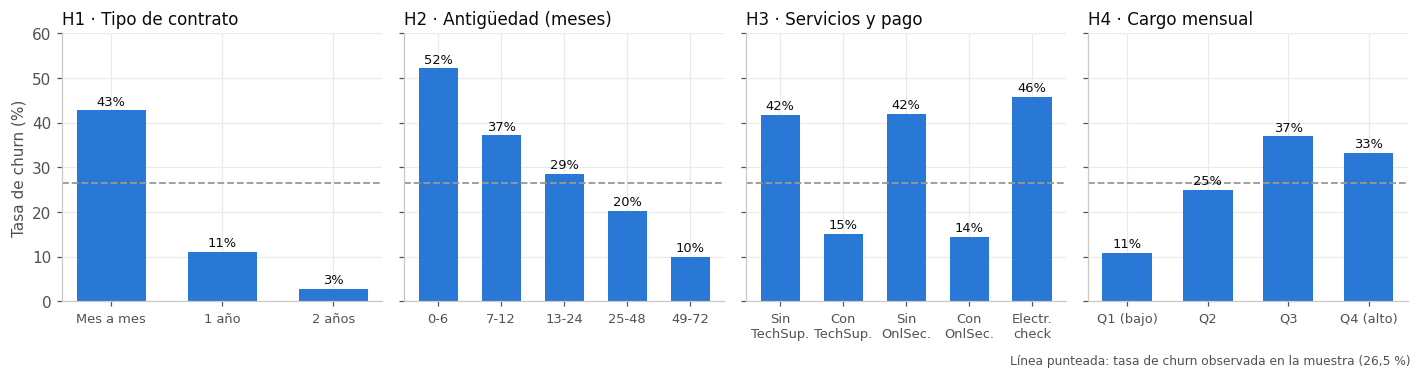

In [8]:
fig, axes = plt.subplots(1, 4, figsize=(13, 3.4), sharey=True)
def barras(ax, etiquetas, tasas, titulo):
    b = ax.bar(range(len(tasas)), np.array(tasas) * 100, color=AZUL, width=0.62)
    ax.axhline(tasa_global * 100, color=GRIS, lw=1.2, ls="--")
    ax.set_xticks(range(len(tasas))); ax.set_xticklabels(etiquetas, rotation=0, fontsize=8.5)
    ax.set_title(titulo, loc="left")
    for r, v in zip(b, tasas):
        ax.text(r.get_x() + r.get_width() / 2, v * 100 + 1.2, f"{v*100:.0f}%", ha="center", fontsize=8.5, color=TINTA)
barras(axes[0], ["Mes a mes", "1 año", "2 años"], h1.tasa_churn, "H1 · Tipo de contrato")
barras(axes[1], h2.tramo_tenure.astype(str), h2.tasa_churn, "H2 · Antigüedad (meses)")
t3 = h3[h3.categoria.isin(["Yes", "No", "Electronic check"])]
lab3 = {("TechSupport", "No"): "Sin\nTechSup.", ("TechSupport", "Yes"): "Con\nTechSup.",
        ("OnlineSecurity", "No"): "Sin\nOnlSec.", ("OnlineSecurity", "Yes"): "Con\nOnlSec.",
        ("PaymentMethod", "Electronic check"): "Electr.\ncheck"}
t3 = t3[[ (v, c) in lab3 for v, c in zip(t3.variable, t3.categoria)]]
barras(axes[2], [lab3[(v, c)] for v, c in zip(t3.variable, t3.categoria)], t3.tasa_churn, "H3 · Servicios y pago")
barras(axes[3], h4.cuartil_cargo.astype(str), h4.tasa_churn, "H4 · Cargo mensual")
axes[0].set_ylabel("Tasa de churn (%)")
axes[0].set_ylim(0, 60)
fig.text(0.99, 0.01, "Línea punteada: tasa de churn observada en la muestra (26,5 %)", ha="right", fontsize=8, color=TINTA2)
fig.tight_layout(rect=(0, 0.03, 1, 1))
fig.savefig(f"{RES}/fig_eda.png", bbox_inches="tight"); plt.show()

**Conclusiones del EDA**
1. **H1:** el contrato mes a mes abandona ~43 %, contra ~11 % (1 año) y ~3 % (2 años).
2. **H2:** el abandono es máximo en los primeros 6 meses (~52 %) y cae de forma monótona con la antigüedad.
3. **H3:** sin TechSupport u OnlineSecurity la tasa ronda 42 %, contra ~15 % con el servicio; Electronic check llega a ~46 %. Ojo: "No internet service" tiene tasa muy baja y mezcla otro perfil de cliente.
4. **H4:** el abandono crece con el cargo mensual, aunque no de forma lineal (el cuartil más bajo, sin internet, es el más estable).
5. Las variables están relacionadas entre sí (contrato, antigüedad y cargos), por lo que el EDA es descriptivo: el aporte propio de cada grupo de variables se mide quitándolas del modelo (sección 6.2).

## 3. Preparación de los datos

| Decisión | Motivo |
|---|---|
| `TotalCharges = 0` cuando `tenure = 0` | El archivo traía la mediana como centinela. |
| Eliminar `customerID` | Identificador sin valor predictivo. |
| `SeniorCitizen` como categoría | Es binaria; se trata igual que el resto de los atributos de perfil. |
| Feature derivada `n_servicios` | Cantidad de servicios adicionales contratados (0-6): resume el "enganche" del cliente (H3). |
| One-Hot para categóricas, escalado para numéricas | Todo dentro de un `Pipeline`, ajustado solo con datos de entrenamiento de cada fold. |

In [9]:
SERVICIOS = ["OnlineSecurity", "OnlineBackup", "DeviceProtection", "TechSupport", "StreamingTV", "StreamingMovies"]

def preparar(df):
    df = df.copy()
    df.loc[df.tenure == 0, "TotalCharges"] = 0.0
    df["SeniorCitizen"] = df["SeniorCitizen"].map({0: "No", 1: "Yes"})
    df["n_servicios"] = (df[SERVICIOS] == "Yes").sum(axis=1)
    return df.drop(columns=["customerID", "Churn"], errors="ignore")

X_all = preparar(train_df)
NUM = ["tenure", "MonthlyCharges", "TotalCharges", "n_servicios"]
CAT = [c for c in X_all.columns if c not in NUM]
print("numéricas:", NUM); print("categóricas:", CAT)

def preprocesador(num=NUM, cat=CAT, escalar=True):
    return ColumnTransformer([
        ("num", StandardScaler() if escalar else "passthrough", num),
        ("cat", OneHotEncoder(handle_unknown="ignore", sparse_output=False), cat)])

numéricas: ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_servicios']
categóricas: ['gender', 'SeniorCitizen', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']


## 4. Modelado: baseline, Random Forest y Gradient Boosting

**Diseño de validación**
- **Holdout estratificado 80/20** sobre `train.csv` (misma semilla que la pre-entrega): el 20 % de test **no se usa para elegir el modelo**.
- **Validación cruzada estratificada de 5 folds** sobre el 80 % de desarrollo para comparar modelos.
- **No hay validación temporal**: el dataset es una foto estática, sin fechas. Es una limitación que se reporta, no se simula.

**Modelos comparados** (cada uno responde una pregunta, no se agregan modelos por agregar):

| Modelo | Pregunta que responde |
|---|---|
| Regresión Logística balanceada | Baseline de la pre-entrega (`class_weight="balanced"`). |
| Regresión Logística sin ponderar | ¿La ponderación cambia el ranking o solo el umbral? |
| Regresión Logística + SMOTE | ¿Sobremuestrear la clase minoritaria (solo en train) mejora el ranking? |
| Random Forest | ¿Un modelo no lineal basado en árboles captura algo que la logística no? |
| Gradient Boosting | ¿Un ensamble secuencial de árboles agrega señal? |

**Regla de selección (fijada antes de mirar el test):** los modelos a menos de un desvío estándar de la mejor PR-AUC media en CV se consideran empatados. Entre empatados se elige el más simple e interpretable, en este orden: logística sin ponderar → logística balanceada → logística + SMOTE → Random Forest → Gradient Boosting.

In [10]:
X_dev, X_test, y_dev, y_test = train_test_split(X_all, y_all, test_size=0.20, random_state=SEED, stratify=y_all)
print("desarrollo:", X_dev.shape, "tasa", round(y_dev.mean(), 4), "| test:", X_test.shape, "tasa", round(y_test.mean(), 4))

MODELOS = {
    "Logística balanceada (pre-entrega)": Pipeline([("prep", preprocesador()), ("clf", LogisticRegression(max_iter=5000, class_weight="balanced", random_state=SEED))]),
    "Logística sin ponderar": Pipeline([("prep", preprocesador()), ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
    "Logística + SMOTE (solo train)": ImbPipeline([("prep", preprocesador()), ("smote", SMOTE(random_state=SEED)), ("clf", LogisticRegression(max_iter=5000, random_state=SEED))]),
    "Random Forest": Pipeline([("prep", preprocesador(escalar=False)), ("clf", RandomForestClassifier(n_estimators=500, min_samples_leaf=5, max_features="sqrt", n_jobs=-1, random_state=SEED))]),
    "Gradient Boosting": Pipeline([("prep", preprocesador(escalar=False)), ("clf", GradientBoostingClassifier(n_estimators=300, learning_rate=0.05, max_depth=3, subsample=0.8, random_state=SEED))]),
}
ORDEN_SIMPLICIDAD = ["Logística sin ponderar", "Logística balanceada (pre-entrega)", "Logística + SMOTE (solo train)", "Random Forest", "Gradient Boosting"]

desarrollo: (4507, 20) tasa 0.2654 | test: (1127, 20) tasa 0.2653


In [11]:
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
filas, pred_cv = [], {}
for nombre, modelo in MODELOS.items():
    pred = np.zeros(len(y_dev))
    for f, (itr, iva) in enumerate(skf.split(X_dev, y_dev)):
        m = clone(modelo).fit(X_dev.iloc[itr], y_dev.iloc[itr])   # SMOTE (si aplica) solo ve itr
        s = m.predict_proba(X_dev.iloc[iva])[:, 1]; pred[iva] = s
        filas.append({"modelo": nombre, "fold": f + 1, **metricas_ranking(y_dev.iloc[iva], s)})
    pred_cv[nombre] = pred
cv = pd.DataFrame(filas)
cv.to_csv(f"{RES}/cv_5folds.csv", index=False)
cv_res = cv.groupby("modelo").agg(**{
    "PR-AUC media": ("PR-AUC", "mean"), "PR-AUC desvío": ("PR-AUC", "std"),
    "ROC-AUC media": ("ROC-AUC", "mean"), "Recall@20% media": ("Recall@20%", "mean"),
    "Precision@20% media": ("Precision@20%", "mean")}).sort_values("PR-AUC media", ascending=False)
cv_res.to_csv(f"{RES}/cv_resumen.csv")
cv_res

,PR-AUC media,PR-AUC desvío,ROC-AUC media,Recall@20% media,Precision@20% media
modelo,,,,,
Logística sin ponderar,0.6588,0.0232,0.8436,0.5042,0.6663
Logística + SMOTE (solo train),0.6588,0.0244,0.8435,0.4983,0.6586
Logística balanceada (pre-entrega),0.6571,0.0243,0.8434,0.5009,0.6619
Random Forest,0.6569,0.0306,0.8429,0.5008,0.6619
Gradient Boosting,0.6531,0.0427,0.8392,0.4858,0.6420


In [12]:
mejor = cv_res["PR-AUC media"].idxmax()
umbral_empate = cv_res.loc[mejor, "PR-AUC media"] - cv_res.loc[mejor, "PR-AUC desvío"]
empatados = cv_res.index[cv_res["PR-AUC media"] >= umbral_empate].tolist()
ELEGIDO = next(m for m in ORDEN_SIMPLICIDAD if m in empatados)
seleccion = pd.DataFrame({"mejor_PR_AUC_CV": [mejor], "umbral_empate": [umbral_empate],
                          "empatados": [", ".join(empatados)], "elegido": [ELEGIDO]})
seleccion.to_csv(f"{RES}/seleccion_modelo.csv", index=False)
print("Mejor PR-AUC media en CV:", mejor, round(cv_res.loc[mejor, "PR-AUC media"], 4))
print("Umbral de empate (media - 1 desvío):", round(umbral_empate, 4))
print("Empatados:", empatados)
print(">>> Modelo elegido por la regla definida de antemano:", ELEGIDO)

Mejor PR-AUC media en CV: Logística sin ponderar 0.6588
Umbral de empate (media - 1 desvío): 0.6356
Empatados: ['Logística sin ponderar', 'Logística + SMOTE (solo train)', 'Logística balanceada (pre-entrega)', 'Random Forest', 'Gradient Boosting']
>>> Modelo elegido por la regla definida de antemano: Logística sin ponderar


## 5. Evaluación en el test (una sola vez)

Todos los modelos se reentrenan con el 80 % de desarrollo y se evalúan **una vez** sobre el 20 % de test. Se compara contra el **ranking aleatorio** (promedio de 2.000 órdenes al azar). Para continuidad con la pre-entrega también se reportan Recall/Precision/F1 con umbral 0,5.

In [13]:
ajustados, scores_test, filas = {}, {}, []
rng = np.random.default_rng(SEED)
azar = pd.DataFrame([metricas_ranking(y_test, rng.random(len(y_test))) for _ in range(2000)]).mean()
filas.append({"modelo": "Ranking aleatorio", **azar.to_dict()})
for nombre, modelo in MODELOS.items():
    m = clone(modelo).fit(X_dev, y_dev); ajustados[nombre] = m
    s = m.predict_proba(X_test)[:, 1]; scores_test[nombre] = s
    yhat = (s >= 0.5).astype(int)
    filas.append({"modelo": nombre, **metricas_ranking(y_test, s),
                  "Recall@0.5": recall_score(y_test, yhat), "Precision@0.5": precision_score(y_test, yhat),
                  "F1@0.5": f1_score(y_test, yhat), "Accuracy@0.5": accuracy_score(y_test, yhat)})
test_metrics = pd.DataFrame(filas).set_index("modelo")
test_metrics.to_csv(f"{RES}/model_metrics.csv")
techo = min(1.0, CUPO / y_test.mean())
print(f"Tasa de churn en el test: {y_test.mean():.4f} | techo de Recall@20%: {techo:.4f}")
test_metrics

Tasa de churn en el test: 0.2653 | techo de Recall@20%: 0.7538


,PR-AUC,ROC-AUC,Recall@20%,Precision@20%,Veces_azar@20%,Recall@0.5,Precision@0.5,F1@0.5,Accuracy@0.5
modelo,,,,,,,,,
Ranking aleatorio,0.2695,0.4999,0.2010,0.2659,1.0021,NaN,NaN,NaN,NaN
Logística balanceada (pre-entrega),0.6662,0.8483,0.5318,0.7035,2.6518,0.7993,0.5241,0.6331,0.7542
Logística sin ponderar,0.6659,0.8482,0.5318,0.7035,2.6518,0.5452,0.6966,0.6116,0.8163
Logística + SMOTE (solo train),0.6668,0.8486,0.5351,0.7080,2.6685,0.7726,0.5286,0.6277,0.7569
Random Forest,0.6550,0.8470,0.5151,0.6814,2.5684,0.4816,0.6990,0.5703,0.8075
Gradient Boosting,0.6734,0.8528,0.5284,0.6991,2.6351,0.5184,0.7078,0.5985,0.8154


### 5.1 Intervalos de confianza

El test tiene ~1.100 clientes y ~300 abandonos: diferencias de 1-2 puntos pueden ser ruido. Se estiman intervalos de confianza del 95 % remuestreando el test 2.000 veces para el modelo elegido y la diferencia contra el mejor modelo de árboles.

In [14]:
arbol = max(["Random Forest", "Gradient Boosting"], key=lambda k: test_metrics.loc[k, "PR-AUC"])
yt = y_test.to_numpy(); se, sa = scores_test[ELEGIDO], scores_test[arbol]
bs = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt))
    if yt[i].sum() == 0: continue
    me, ma = metricas_ranking(yt[i], se[i]), metricas_ranking(yt[i], sa[i])
    bs.append({"PR-AUC elegido": me["PR-AUC"], "Recall@20% elegido": me["Recall@20%"],
               f"Δ PR-AUC (elegido − {arbol})": me["PR-AUC"] - ma["PR-AUC"],
               f"Δ Recall@20% (elegido − {arbol})": me["Recall@20%"] - ma["Recall@20%"]})
bs = pd.DataFrame(bs)
ic = bs.quantile([0.025, 0.5, 0.975]).T.rename(columns={0.025: "IC 2,5 %", 0.5: "mediana", 0.975: "IC 97,5 %"})
ic.to_csv(f"{RES}/intervalos_confianza.csv")
ic

,"IC 2,5 %",mediana,"IC 97,5 %"
PR-AUC elegido,0.6096,0.6681,0.7271
Recall@20% elegido,0.4917,0.5340,0.5786
Δ PR-AUC (elegido − Gradient Boosting),-0.0343,-0.0079,0.0181
Δ Recall@20% (elegido − Gradient Boosting),-0.0234,0.0068,0.0363


### 5.2 Curvas precisión-recall y de ganancia; abandonos por decil

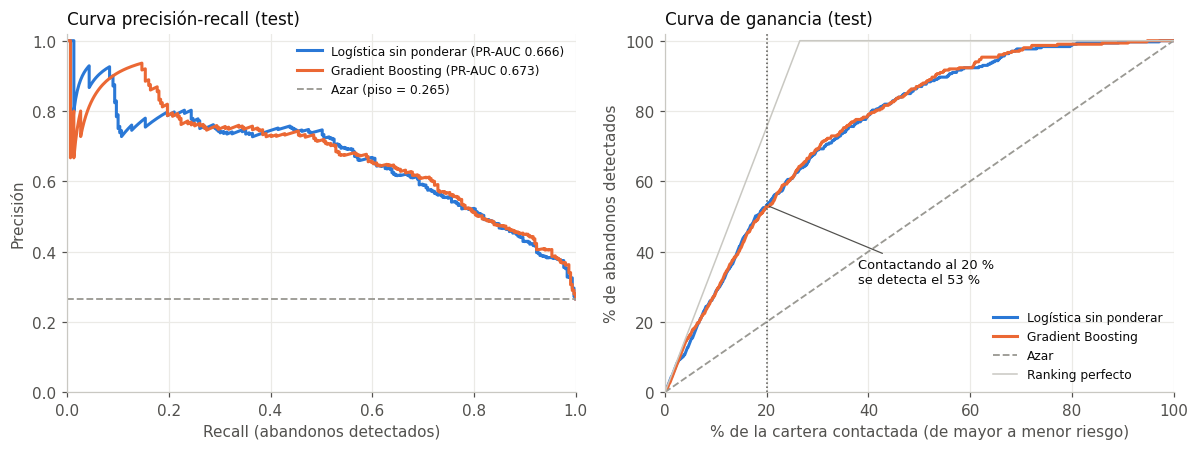

In [15]:
COLORES = {ELEGIDO: AZUL, arbol: NARANJA}
fig, (a1, a2) = plt.subplots(1, 2, figsize=(11, 4.2))
for nombre in [ELEGIDO, arbol]:
    p, r, _ = precision_recall_curve(y_test, scores_test[nombre])
    a1.plot(r, p, color=COLORES[nombre], lw=2, label=f"{nombre} (PR-AUC {test_metrics.loc[nombre,'PR-AUC']:.3f})")
a1.axhline(y_test.mean(), color=GRIS, ls="--", lw=1.2, label=f"Azar (piso = {y_test.mean():.3f})")
a1.set_xlabel("Recall (abandonos detectados)"); a1.set_ylabel("Precisión"); a1.set_title("Curva precisión-recall (test)", loc="left")
a1.set_xlim(0, 1); a1.set_ylim(0, 1.02); a1.legend(fontsize=8, frameon=False, loc="upper right")

frac = np.arange(1, len(y_test) + 1) / len(y_test)
for nombre in [ELEGIDO, arbol]:
    orden = np.argsort(-scores_test[nombre], kind="mergesort")
    a2.plot(frac * 100, np.cumsum(yt[orden]) / yt.sum() * 100, color=COLORES[nombre], lw=2, label=nombre)
a2.plot([0, 100], [0, 100], color=GRIS, ls="--", lw=1.2, label="Azar")
a2.plot([0, y_test.mean() * 100, 100], [0, 100, 100], color="#c9c8c2", lw=1, label="Ranking perfecto")
a2.axvline(CUPO * 100, color=TINTA2, lw=1, ls=":")
r20 = test_metrics.loc[ELEGIDO, "Recall@20%"] * 100
a2.annotate(f"Contactando al 20 %\nse detecta el {r20:.0f} %", xy=(20, r20), xytext=(38, r20 - 22),
            fontsize=8.5, color=TINTA, arrowprops=dict(arrowstyle="-", color=TINTA2, lw=0.8))
a2.set_xlabel("% de la cartera contactada (de mayor a menor riesgo)"); a2.set_ylabel("% de abandonos detectados")
a2.set_title("Curva de ganancia (test)", loc="left"); a2.set_xlim(0, 100); a2.set_ylim(0, 102)
a2.legend(fontsize=8, frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(f"{RES}/fig_pr_ganancia.png", bbox_inches="tight"); plt.show()

In [16]:
def tabla_cupos(y, s, cupos=(0.10, 0.20, 0.30, 0.40, 0.50)):
    return pd.DataFrame([{"cupo": c, **{k: v for k, v in metricas_ranking(y, s, c).items() if k not in ("PR-AUC", "ROC-AUC")}}
                         for c in cupos]).rename(columns=lambda c: c.replace("@20%", ""))
cupos = tabla_cupos(y_test, scores_test[ELEGIDO])
cupos.to_csv(f"{RES}/captura_por_cupo.csv", index=False)

orden = np.argsort(-scores_test[ELEGIDO], kind="mergesort")
dec = pd.DataFrame({"y": yt[orden], "decil": np.repeat(np.arange(1, 11), np.diff(np.linspace(0, len(yt), 11).round().astype(int)))})
deciles = dec.groupby("decil")["y"].agg(clientes="size", abandonos="sum", tasa="mean").reset_index()
deciles["veces_azar"] = deciles.tasa / yt.mean()
deciles["recall_acumulado"] = deciles.abandonos.cumsum() / yt.sum()
deciles.to_csv(f"{RES}/abandonos_por_decil.csv", index=False)
display(cupos); deciles

,cupo,Recall,Precision,Veces_azar
0,0.1000,0.2876,0.7611,2.8686
1,0.2000,0.5318,0.7035,2.6518
2,0.3000,0.6890,0.6077,2.2904
3,0.4000,0.7893,0.5233,1.9724
4,0.5000,0.8696,0.4610,1.7376


,decil,clientes,abandonos,tasa,veces_azar,recall_acumulado
0,1,113,86,0.7611,2.8686,0.2876
1,2,112,73,0.6518,2.4567,0.5318
2,3,113,47,0.4159,1.5677,0.6890
3,4,113,30,0.2655,1.0007,0.7893
4,5,113,24,0.2124,0.8005,0.8696
5,6,112,16,0.1429,0.5385,0.9231
6,7,113,16,0.1416,0.5337,0.9766
7,8,113,3,0.0265,0.1001,0.9866
8,9,112,3,0.0268,0.1010,0.9967
9,10,113,1,0.0088,0.0334,1.0000


### 5.3 Probabilidades y umbral

El ranking no depende de la escala del score, pero si el área quiere leer el score como probabilidad hay que comparar las probabilidades predichas con las tasas reales. La ponderación de clases y SMOTE **inflan** las probabilidades (el modelo "cree" que la mitad de los clientes abandona); la logística sin ponderar queda cerca de la diagonal.

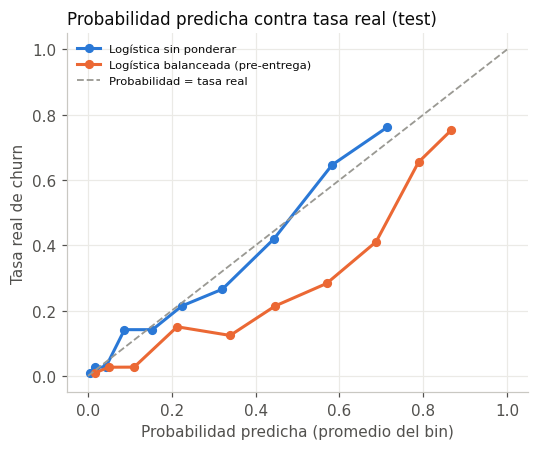

Matriz de confusión (test, umbral F1):
 [[662 166]
 [ 82 217]]


,umbral_F1,Recall,Precision,F1,Accuracy,% marcado Sí
0,0.3282,0.7258,0.5666,0.6364,0.7799,0.3398


In [17]:
fig, ax = plt.subplots(figsize=(5, 4.2))
for nombre, color in [(ELEGIDO, AZUL), ("Logística balanceada (pre-entrega)", NARANJA)]:
    if nombre == ELEGIDO and nombre == "Logística balanceada (pre-entrega)": continue
    pt, pp = calibration_curve(y_test, scores_test[nombre], n_bins=10, strategy="quantile")
    ax.plot(pp, pt, marker="o", ms=5, lw=2, color=color, label=nombre)
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1.2, label="Probabilidad = tasa real")
ax.set_xlabel("Probabilidad predicha (promedio del bin)"); ax.set_ylabel("Tasa real de churn")
ax.set_title("Probabilidad predicha contra tasa real (test)", loc="left"); ax.legend(fontsize=7.5, frameon=False)
fig.tight_layout(); fig.savefig(f"{RES}/fig_probabilidades.png", bbox_inches="tight"); plt.show()

# Umbral para etiquetar Sí/No: se elige con las predicciones de la validación cruzada (no con el test)
p_, r_, t_ = precision_recall_curve(y_dev, pred_cv[ELEGIDO])
f1s = 2 * p_[:-1] * r_[:-1] / np.clip(p_[:-1] + r_[:-1], 1e-9, None)
UMBRAL_F1 = float(t_[np.nanargmax(f1s)])
yhat = (scores_test[ELEGIDO] >= UMBRAL_F1).astype(int)
umbral = pd.DataFrame([{"umbral_F1": UMBRAL_F1, "Recall": recall_score(y_test, yhat), "Precision": precision_score(y_test, yhat),
                        "F1": f1_score(y_test, yhat), "Accuracy": accuracy_score(y_test, yhat), "% marcado Sí": yhat.mean()}])
umbral.to_csv(f"{RES}/umbral_f1.csv", index=False)
print("Matriz de confusión (test, umbral F1):\n", confusion_matrix(y_test, yhat))
umbral

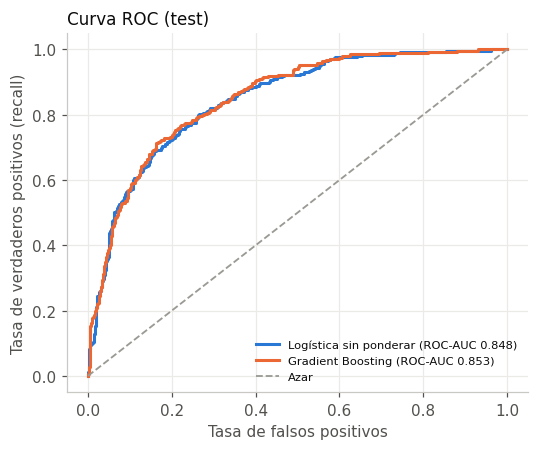

,Predicho: No,Predicho: Sí
Real: No abandona,662,166
Real: Abandona,82,217


,precision,recall,f1-score,support
No abandona,0.8898,0.7995,0.8422,828.0000
Abandona,0.5666,0.7258,0.6364,299.0000
accuracy,0.7799,0.7799,0.7799,0.7799
macro avg,0.7282,0.7626,0.7393,"1,127.0000"
weighted avg,0.8040,0.7799,0.7876,"1,127.0000"


In [18]:
# Matriz de confusión y reporte por clase (umbral elegido con la validación cruzada) + curva ROC
from sklearn.metrics import classification_report, roc_curve
cm_ = confusion_matrix(y_test, yhat)
pd.DataFrame(cm_, index=["Real: No abandona", "Real: Abandona"], columns=["Predicho: No", "Predicho: Sí"]).to_csv(f"{RES}/matriz_confusion.csv")
rep = pd.DataFrame(classification_report(y_test, yhat, target_names=["No abandona", "Abandona"], output_dict=True)).T
rep.to_csv(f"{RES}/reporte_clasificacion.csv")
fig, ax = plt.subplots(figsize=(5, 4.2))
for nombre, color in [(ELEGIDO, AZUL), (arbol, NARANJA)]:
    fpr, tpr, _ = roc_curve(y_test, scores_test[nombre])
    ax.plot(fpr, tpr, lw=2, color=color, label=f"{nombre} (ROC-AUC {test_metrics.loc[nombre,'ROC-AUC']:.3f})")
ax.plot([0, 1], [0, 1], color=GRIS, ls="--", lw=1.2, label="Azar")
ax.set_xlabel("Tasa de falsos positivos"); ax.set_ylabel("Tasa de verdaderos positivos (recall)")
ax.set_title("Curva ROC (test)", loc="left"); ax.legend(fontsize=7.5, frameon=False, loc="lower right")
fig.tight_layout(); fig.savefig(f"{RES}/fig_roc.png", bbox_inches="tight"); plt.show()
display(pd.DataFrame(cm_, index=["Real: No abandona", "Real: Abandona"], columns=["Predicho: No", "Predicho: Sí"])); rep

## 6. Interpretación del modelo

### 6.1 SHAP

Se explica el modelo elegido sobre el test. Las columnas one-hot se **suman por variable original**, así el negocio lee "Contract" y no tres columnas. SHAP describe cómo razona el modelo; **no demuestra causalidad**.

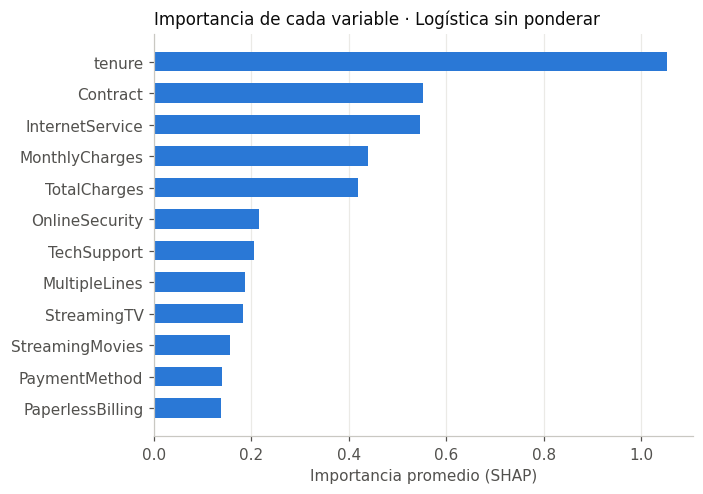

,mean|SHAP|,escala
tenure,1.0540,lineal
Contract,0.5520,lineal
InternetService,0.5458,lineal
MonthlyCharges,0.4393,lineal
TotalCharges,0.4181,lineal
OnlineSecurity,0.2155,lineal
TechSupport,0.2052,lineal
MultipleLines,0.1876,lineal
StreamingTV,0.1833,lineal
StreamingMovies,0.1569,lineal


In [19]:
modelo_e = ajustados[ELEGIDO]
prep_e = modelo_e.named_steps["prep"]; clf_e = modelo_e.named_steps["clf"]
Xt_dev = prep_e.transform(X_dev); Xt_test = prep_e.transform(X_test)
nombres = prep_e.get_feature_names_out()
def original(n):
    n = n.split("__", 1)[1]
    for c in CAT:
        if n.startswith(c + "_"): return c
    return n
grupo = np.array([original(n) for n in nombres])

if isinstance(clf_e, LogisticRegression):
    explainer = shap.LinearExplainer(clf_e, Xt_dev); escala = "lineal"
else:
    explainer = shap.TreeExplainer(clf_e); escala = "lineal" if isinstance(clf_e, GradientBoostingClassifier) else "probabilidad"
sv = explainer.shap_values(Xt_test)
if isinstance(sv, list): sv = sv[1]
if sv.ndim == 3: sv = sv[:, :, 1]
sv_g = pd.DataFrame(sv, columns=grupo).T.groupby(level=0).sum().T
shap_global = sv_g.abs().mean().sort_values(ascending=False).rename("mean|SHAP|").to_frame()
shap_global["escala"] = escala
shap_global.to_csv(f"{RES}/shap_global.csv")

fig, ax = plt.subplots(figsize=(6.5, 4.6))
top = shap_global["mean|SHAP|"].head(12)[::-1]
ax.barh(top.index, top.values, color=AZUL, height=0.62)
ax.set_xlabel("Importancia promedio (SHAP)"); ax.set_title(f"Importancia de cada variable · {ELEGIDO}", loc="left")
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{RES}/fig_shap_global.png", bbox_inches="tight"); plt.show()
shap_global.head(12)

In [20]:
# Dirección del efecto: SHAP medio por categoría de las variables clave
filas = []
for var in ["Contract", "InternetService", "PaymentMethod", "TechSupport", "OnlineSecurity"]:
    for cat_, idx in X_test.groupby(var).groups.items():
        pos = X_test.index.get_indexer(idx)
        filas.append({"variable": var, "categoria": cat_, "clientes": len(pos), "SHAP medio": sv_g[var].iloc[pos].mean()})
for var in ["tenure", "MonthlyCharges", "n_servicios"]:
    q = pd.qcut(X_test[var].rank(method="first"), 3, labels=["bajo", "medio", "alto"])
    for cat_ in ["bajo", "medio", "alto"]:
        pos = np.where(q == cat_)[0]
        filas.append({"variable": var, "categoria": f"tercil {cat_}", "clientes": len(pos), "SHAP medio": sv_g[var].iloc[pos].mean()})
shap_dir = pd.DataFrame(filas); shap_dir.to_csv(f"{RES}/shap_direccion.csv", index=False)
shap_dir

,variable,categoria,clientes,SHAP medio
0,Contract,Month-to-month,602,0.4915
1,Contract,One year,255,-0.2256
2,Contract,Two year,270,-0.9953
3,InternetService,DSL,366,-0.7179
4,InternetService,Fiber optic,517,0.5265
5,InternetService,No,244,-0.3287
6,PaymentMethod,Bank transfer (automatic),251,-0.1308
7,PaymentMethod,Credit card (automatic),252,-0.1765
8,PaymentMethod,Electronic check,381,0.1671
9,PaymentMethod,Mailed check,243,-0.0672


Valor base: -1.519 | suma: 0.632 | score del modelo: 0.653 | sigmoide(suma): 0.653


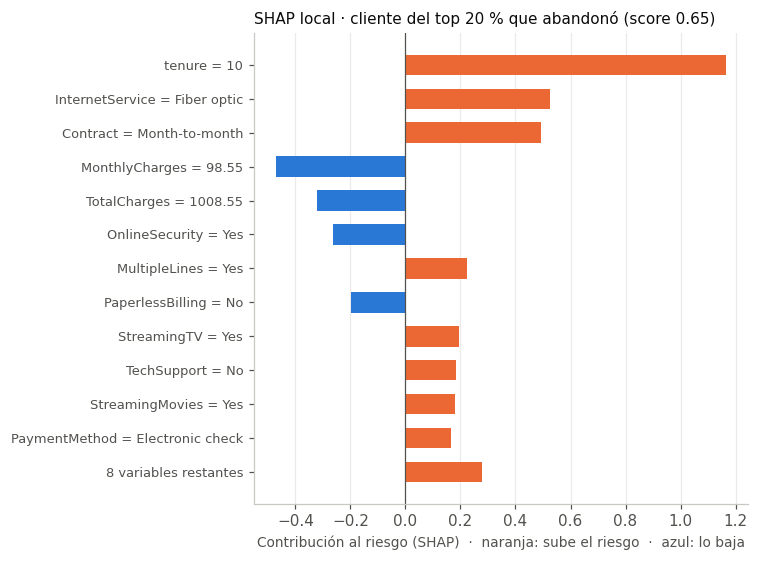

,variable,valor,contribucion
0,tenure,10,1.1636
1,InternetService,Fiber optic,0.5265
2,Contract,Month-to-month,0.4915
3,MonthlyCharges,98.5500,-0.4692
4,TotalCharges,"1,008.5500",-0.3232
5,OnlineSecurity,Yes,-0.2650
6,MultipleLines,Yes,0.2231
7,PaperlessBilling,No,-0.1993
8,StreamingTV,Yes,0.1946
9,TechSupport,No,0.1826


In [21]:
# Caso local: un cliente real del test que abandonó y quedó dentro del top 20 %
n_top = int(math.ceil(CUPO * len(yt)))
top_idx = np.argsort(-scores_test[ELEGIDO], kind="mergesort")[:n_top]
cand = [i for i in top_idx if yt[i] == 1]
i0 = cand[len(cand) // 2]                      # caso "típico" dentro del top, no el extremo
base = float(np.ravel(explainer.expected_value)[-1])
fila = sv_g.iloc[i0].sort_values(key=np.abs, ascending=False)
caso = pd.DataFrame({"variable": fila.index, "valor": [X_test.iloc[i0][v] for v in fila.index], "contribucion": fila.values})
caso.to_csv(f"{RES}/shap_local_case.csv", index=False)
logit = base + fila.sum()
print(f"Valor base: {base:.3f} | suma: {logit:.3f} | score del modelo: {scores_test[ELEGIDO][i0]:.3f}"
      + (f" | sigmoide(suma): {1/(1+np.exp(-logit)):.3f}" if escala == "lineal" else ""))

k = 12
show = caso.head(k).iloc[::-1]
otros = caso.contribucion.iloc[k:].sum()
fig, ax = plt.subplots(figsize=(7, 5.2))
etq = [f"{v} = {x}" for v, x in zip(show.variable, show.valor)]
etq = [f"{len(caso)-k} variables restantes"] + etq
vals = np.r_[otros, show.contribucion.values]
ax.barh(range(len(vals)), vals, color=[NARANJA if v > 0 else AZUL for v in vals], height=0.6)
ax.set_yticks(range(len(vals))); ax.set_yticklabels(etq, fontsize=8.5); ax.axvline(0, color=TINTA2, lw=0.8)
ax.set_xlabel("Contribución al riesgo (SHAP)  ·  naranja: sube el riesgo  ·  azul: lo baja", fontsize=9)
ax.set_title(f"SHAP local · cliente del top 20 % que abandonó (score {scores_test[ELEGIDO][i0]:.2f})", loc="left", fontsize=10)
ax.grid(axis="y", visible=False)
fig.tight_layout(); fig.savefig(f"{RES}/fig_shap_local.png", bbox_inches="tight"); plt.show()
caso.head(10)

### 6.2 Prueba de quitar variables

Se reentrena el modelo elegido **sin** cada bloque de variables y se mide la caída sobre el **mismo test**. Como las variables están correlacionadas, una caída chica no significa que el factor no importe: puede significar que otra variable cuenta la misma historia.

In [22]:
BLOQUES = {"H1: sin Contract": ["Contract"],
           "H2: sin antigüedad (tenure, TotalCharges)": ["tenure", "TotalCharges"],
           "H3: sin servicios y pago (TechSupport, OnlineSecurity, n_servicios, PaymentMethod)": ["TechSupport", "OnlineSecurity", "n_servicios", "PaymentMethod"],
           "H4: sin MonthlyCharges": ["MonthlyCharges"],
           "Contrato + antigüedad juntos": ["Contract", "tenure", "TotalCharges"]}
ref = metricas_ranking(y_test, scores_test[ELEGIDO])
filas = [{"bloque": "Modelo completo", "PR-AUC": ref["PR-AUC"], "Recall@20%": ref["Recall@20%"], "Δ PR-AUC": 0.0, "Δ Recall@20%": 0.0}]
for nombre, quitar in BLOQUES.items():
    num = [c for c in NUM if c not in quitar]; cat = [c for c in CAT if c not in quitar]
    m = clone(MODELOS[ELEGIDO]); m.steps[0] = ("prep", preprocesador(num, cat, escalar=not ("Random" in ELEGIDO or "Gradient" in ELEGIDO)))
    m.fit(X_dev, y_dev); r = metricas_ranking(y_test, m.predict_proba(X_test)[:, 1])
    filas.append({"bloque": nombre, "PR-AUC": r["PR-AUC"], "Recall@20%": r["Recall@20%"],
                  "Δ PR-AUC": r["PR-AUC"] - ref["PR-AUC"], "Δ Recall@20%": r["Recall@20%"] - ref["Recall@20%"]})
quitar_vars = pd.DataFrame(filas); quitar_vars.to_csv(f"{RES}/quitar_variables.csv", index=False)
quitar_vars

,bloque,PR-AUC,Recall@20%,Δ PR-AUC,Δ Recall@20%
0,Modelo completo,0.6659,0.5318,0.0000,0.0000
1,H1: sin Contract,0.6628,0.5351,-0.0031,0.0033
2,"H2: sin antigüedad (tenure, TotalCharges)",0.6094,0.4849,-0.0565,-0.0468
3,"H3: sin servicios y pago (TechSupport, OnlineS...",0.6597,0.5351,-0.0062,0.0033
4,H4: sin MonthlyCharges,0.6668,0.5318,0.0008,0.0000
5,Contrato + antigüedad juntos,0.5901,0.4749,-0.0758,-0.0569


## 7. Auditoría por grupos (ética)

Para cada grupo se reporta qué parte de la cartera representa, qué parte del top 20 % ocupa y el recall dentro del grupo. `gender` y `SeniorCitizen` (edad) son atributos sensibles. Una diferencia en la tasa real de churn entre grupos **no prueba** que no haya sesgo, ni justifica automáticamente un trato distinto.

In [23]:
sel = np.zeros(len(yt), bool); sel[top_idx] = True
filas = []
for var in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    for g in sorted(X_test[var].unique()):
        mk = (X_test[var] == g).to_numpy()
        filas.append({"atributo": var, "grupo": g, "clientes": int(mk.sum()), "tasa_real": yt[mk].mean(),
                      "% de la cartera": mk.mean(), "% del top 20": sel[mk].sum() / sel.sum(),
                      "seleccionados del grupo": sel[mk].mean(),
                      "recall del grupo": (sel & mk & (yt == 1)).sum() / max(1, (mk & (yt == 1)).sum())})
auditoria = pd.DataFrame(filas); auditoria.to_csv(f"{RES}/auditoria_grupos.csv", index=False)

# ¿Qué pasa si se quitan los atributos sensibles?
sens = ["gender", "SeniorCitizen"]
m = clone(MODELOS[ELEGIDO]); m.steps[0] = ("prep", preprocesador(NUM, [c for c in CAT if c not in sens], escalar=not ("Random" in ELEGIDO or "Gradient" in ELEGIDO)))
m.fit(X_dev, y_dev); r = metricas_ranking(y_test, m.predict_proba(X_test)[:, 1])
s_ss = m.predict_proba(X_test)[:, 1]
sel_ss = np.zeros(len(yt), bool); sel_ss[np.argsort(-s_ss, kind="mergesort")[:n_top]] = True
def recall_grupo(sel_, var, g):
    mk = (X_test[var] == g).to_numpy(); return (sel_ & mk & (yt == 1)).sum() / (mk & (yt == 1)).sum()
sin_sensibles = pd.DataFrame([{"modelo": "Sin gender ni SeniorCitizen", **r,
                               "recall Female": recall_grupo(sel_ss, "gender", "Female"), "recall Male": recall_grupo(sel_ss, "gender", "Male")},
                              {"modelo": "Modelo completo", **ref,
                               "recall Female": recall_grupo(sel, "gender", "Female"), "recall Male": recall_grupo(sel, "gender", "Male")}])
# ¿La brecha de recall por género es mayor que la esperable por azar? Intervalo de confianza remuestreando el test
brecha = []
for _ in range(2000):
    i = rng.integers(0, len(yt), len(yt)); f_ = (X_test.gender.to_numpy()[i] == "Female")
    yy, ss = yt[i], sel[i]
    brecha.append((ss & f_ & (yy == 1)).sum() / max(1, (f_ & (yy == 1)).sum()) - (ss & ~f_ & (yy == 1)).sum() / max(1, (~f_ & (yy == 1)).sum()))
print("Brecha de recall Female − Male, IC 95 %:", np.round(np.quantile(brecha, [0.025, 0.5, 0.975]), 3))
pd.DataFrame({"brecha_recall_F_menos_M": np.quantile(brecha, [0.025, 0.5, 0.975])}, index=["IC 2,5 %", "mediana", "IC 97,5 %"]).to_csv(f"{RES}/brecha_genero_ic.csv")
sin_sensibles.to_csv(f"{RES}/sin_atributos_sensibles.csv", index=False)
display(auditoria); sin_sensibles

Brecha de recall Female − Male, IC 95 %: [0.051 0.166 0.283]


,atributo,grupo,clientes,tasa_real,% de la cartera,% del top 20,seleccionados del grupo,recall del grupo
0,gender,Female,565,0.2549,0.5013,0.5708,0.2283,0.6181
1,gender,Male,562,0.2758,0.4987,0.4292,0.1726,0.4516
2,SeniorCitizen,No,936,0.2340,0.8305,0.6726,0.1624,0.4840
3,SeniorCitizen,Yes,191,0.4188,0.1695,0.3274,0.3874,0.6625
4,Partner,No,574,0.3136,0.5093,0.6726,0.2648,0.5833
5,Partner,Yes,553,0.2152,0.4907,0.3274,0.1338,0.4538
6,Dependents,No,799,0.3016,0.7090,0.8761,0.2478,0.5768
7,Dependents,Yes,328,0.1768,0.2910,0.1239,0.0854,0.3448


,modelo,PR-AUC,ROC-AUC,Recall@20%,Precision@20%,Veces_azar@20%,recall Female,recall Male
0,Sin gender ni SeniorCitizen,0.6642,0.8481,0.5385,0.7124,2.6852,0.6250,0.4581
1,Modelo completo,0.6659,0.8482,0.5318,0.7035,2.6518,0.6181,0.4516


**Contraste con el desarrollo.** El test tiene solo ~150 abandonos por género, así que una brecha puede ser propia de esa muestra. Se repite la auditoría con las predicciones de la validación cruzada (4.507 clientes, cada uno puntuado por un modelo que no lo vio).

In [24]:
s_cv, yd = pred_cv[ELEGIDO], y_dev.to_numpy()
n_d = int(math.ceil(CUPO * len(yd))); sel_d = np.zeros(len(yd), bool); sel_d[np.argsort(-s_cv, kind="mergesort")[:n_d]] = True
filas = []
for var in ["gender", "SeniorCitizen", "Partner", "Dependents"]:
    for g in sorted(X_dev[var].unique()):
        mk = (X_dev[var] == g).to_numpy()
        filas.append({"atributo": var, "grupo": g, "clientes": int(mk.sum()), "tasa_real": yd[mk].mean(),
                      "seleccionados del grupo": sel_d[mk].mean(),
                      "recall del grupo (validación cruzada)": (sel_d & mk & (yd == 1)).sum() / (mk & (yd == 1)).sum()})
auditoria_cv = pd.DataFrame(filas); auditoria_cv.to_csv(f"{RES}/auditoria_grupos_validacion_cruzada.csv", index=False)
auditoria_cv

,atributo,grupo,clientes,tasa_real,seleccionados del grupo,recall del grupo (validación cruzada)
0,gender,Female,2236,0.2692,0.2089,0.5033
1,gender,Male,2271,0.2616,0.1915,0.4949
2,SeniorCitizen,No,3778,0.2377,0.1612,0.4465
3,SeniorCitizen,Yes,729,0.4088,0.4019,0.6577
4,Partner,No,2331,0.3312,0.2728,0.5557
5,Partner,Yes,2176,0.1949,0.1222,0.3962
6,Dependents,No,3156,0.3165,0.2601,0.5495
7,Dependents,Yes,1351,0.1458,0.0600,0.2437


## 8. Traducción a negocio

**Pregunta de la devolución:** si se contacta al 20 % de clientes con mayor riesgo, ¿qué porcentaje de los que realmente abandonan se detecta? La respuesta sale de la curva de ganancia (sección 5.2).

**Valor del cliente y costo de retenerlo.** Retener a un cliente suele ser más barato que conseguir uno nuevo, pero solo vale la pena rescatar a los clientes que **valen más de lo que cuesta retenerlos**. Supuestos genéricos (no son datos de la empresa):
- **Valor del cliente en su ciclo de vida** = `MonthlyCharges` × **24 meses** de permanencia esperada (el ciclo de vida termina también por causas ajenas al servicio: mudanzas, cierre de cuentas, etc.).
- La acción de retención logra quedarse con el **30 %** de los clientes contactados que iban a irse.
- **Costo por cliente retenido:** escenarios de **USD 100, 1.000 y 10.000**.
- Solo se contacta a clientes cuyo valor supera el costo de retenerlos; si retener cuesta más de lo que el cliente vale, conviene invertir ese dinero en conseguir uno nuevo.

Se comparan tres formas de usar el cupo del 20 %: **al azar**, **por riesgo** (el ranking del modelo) y **por valor en riesgo** (probabilidad de abandono × valor del cliente), que prioriza a los clientes que se van **y** gastan mucho. Se calcula sobre el test y se escala a una cartera de 10.000 clientes.

In [25]:
MESES_VIDA, EXITO, CARTERA = 24, 0.30, 10_000
COSTOS = [100, 1_000, 10_000]
mc = X_test["MonthlyCharges"].to_numpy()
valor = mc * MESES_VIDA                                  # valor del cliente en su ciclo de vida
p_test = scores_test[ELEGIDO]
f = CARTERA / len(yt)
print(f"Valor del cliente: promedio USD {valor.mean():,.0f} | de los que abandonan USD {valor[yt == 1].mean():,.0f} | máximo USD {valor.max():,.0f}")

def campania(orden, costo):
    elegibles = orden[valor[orden] > costo]               # solo si el cliente vale más que retenerlo
    idx = elegibles[:n_top]
    det = idx[yt[idx] == 1]
    retenidos = EXITO * len(det)
    preservado = EXITO * valor[det].sum()
    gasto = costo * retenidos
    return {"contactados": len(idx) * f, "abandonos detectados": len(det) * f, "clientes retenidos": retenidos * f,
            "valor preservado USD": preservado * f, "costo de retención USD": gasto * f, "valor neto USD": (preservado - gasto) * f}

orden_riesgo = np.argsort(-p_test, kind="mergesort")
orden_valor = np.argsort(-(p_test * valor), kind="mergesort")
filas = []
for costo in COSTOS:
    filas.append({"costo por retenido USD": costo, "estrategia": "Por valor en riesgo", **campania(orden_valor, costo)})
    filas.append({"costo por retenido USD": costo, "estrategia": "Por riesgo", **campania(orden_riesgo, costo)})
    azar = pd.DataFrame([campania(rng.permutation(len(yt)), costo) for _ in range(500)]).mean()
    filas.append({"costo por retenido USD": costo, "estrategia": "Al azar", **azar.to_dict()})
valor_cliente = pd.DataFrame(filas)
valor_cliente.to_csv(f"{RES}/valor_cliente_escenarios.csv", index=False)
valor_cliente.round(0)

Valor del cliente: promedio USD 1,581 | de los que abandonan USD 1,841 | máximo USD 2,807


,costo por retenido USD,estrategia,contactados,abandonos detectados,clientes retenidos,valor preservado USD,costo de retención USD,valor neto USD
0,100,Por valor en riesgo,"2,005.0000","1,366.0000",410.0000,"864,578.0000","40,994.0000","823,584.0000"
1,100,Por riesgo,"2,005.0000","1,411.0000",423.0000,"845,974.0000","42,325.0000","803,650.0000"
2,100,Al azar,"2,005.0000",527.0000,158.0000,"292,286.0000","15,818.0000","276,469.0000"
3,1000,Por valor en riesgo,"2,005.0000","1,366.0000",410.0000,"864,578.0000","409,938.0000","454,640.0000"
4,1000,Por riesgo,"2,005.0000","1,393.0000",418.0000,"855,819.0000","417,924.0000","437,896.0000"
5,1000,Al azar,"2,005.0000",654.0000,196.0000,"386,152.0000","196,243.0000","189,909.0000"
6,10000,Por valor en riesgo,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
7,10000,Por riesgo,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000
8,10000,Al azar,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000


### 8.1 Ciclo de vida y gasto del cliente

En telecomunicaciones el gasto es mensual y recurrente (alta periodicidad), así que el valor de un cliente depende de cuántos meses sigue activo y de cuánto paga por mes. Los datos dan una referencia del ciclo de vida.

In [26]:
tr = train_df.assign(abandona=(train_df.Churn == "Yes"))
ciclo = tr.groupby("Contract").agg(clientes=("tenure", "size"), tasa_abandono=("abandona", "mean"),
                                   meses_activos_promedio=("tenure", "mean"), cargo_mensual_promedio=("MonthlyCharges", "mean"))
ciclo.loc["Total"] = [len(tr), tr.abandona.mean(), tr.tenure.mean(), tr.MonthlyCharges.mean()]
ciclo["meses_hasta_abandonar (los que se fueron)"] = list(tr[tr.abandona].groupby("Contract").tenure.mean()) + [tr[tr.abandona].tenure.mean()]
ciclo.to_csv(f"{RES}/ciclo_vida_gasto.csv")
print(f"Los que abandonaron duraron en promedio {tr[tr.abandona].tenure.mean():.1f} meses (mediana {tr[tr.abandona].tenure.median():.0f}); "
      f"los que siguen activos ya llevan {tr[~tr.abandona].tenure.mean():.1f} meses.")
print(f"Cargo mensual promedio: los que abandonan USD {tr[tr.abandona].MonthlyCharges.mean():.1f}, los que se quedan USD {tr[~tr.abandona].MonthlyCharges.mean():.1f}.")
ciclo.round(2)

Los que abandonaron duraron en promedio 18.4 meses (mediana 10); los que siguen activos ya llevan 37.6 meses.
Cargo mensual promedio: los que abandonan USD 74.9, los que se quedan USD 61.3.


,clientes,tasa_abandono,meses_activos_promedio,cargo_mensual_promedio,meses_hasta_abandonar (los que se fueron)
Contract,,,,,
Month-to-month,"3,102.0000",0.4300,18.1300,66.4900,14.3700
One year,"1,173.0000",0.1100,42.4400,65.5000,46.0500
Two year,"1,359.0000",0.0300,56.6500,60.8700,61.6400
Total,"5,634.0000",0.2700,32.4900,64.9300,18.3600


### 8.2 Segmentación por valor y riesgo

No todos los clientes se rescatan por igual. Se cruzan dos ejes sobre el test:
- **Valor:** alto si el valor en el ciclo de vida (`MonthlyCharges` × 24) supera la mediana de la cartera.
- **Riesgo:** alto si el cliente está dentro del 20 % con mayor probabilidad de abandono según el modelo.

| Segmento | Valor | Riesgo | Acción |
|---|---|---|---|
| **Golden** | Alto | Alto | Rescatar: contacto personalizado e incentivo. |
| **Champions** | Alto | Bajo | Fidelizar sin descuento (beneficios de permanencia). |
| **En riesgo de bajo valor** | Bajo | Alto | Solo acciones de bajo costo (mensajes automáticos). |
| **Estables de bajo valor** | Bajo | Bajo | Sin acción. |

In [27]:
VALOR_CORTE = np.median(valor)
alto_valor = valor >= VALOR_CORTE
alto_riesgo = np.zeros(len(yt), bool); alto_riesgo[orden_riesgo[:n_top]] = True
seg = np.select([alto_valor & alto_riesgo, alto_valor & ~alto_riesgo, ~alto_valor & alto_riesgo],
                ["Golden", "Champions", "En riesgo de bajo valor"], "Estables de bajo valor")
ACCION = {"Golden": "Rescatar: contacto personalizado e incentivo",
          "Champions": "Fidelizar sin descuento",
          "En riesgo de bajo valor": "Acciones de bajo costo (mensajes automáticos)",
          "Estables de bajo valor": "Sin acción"}
filas = []
for nombre in ["Golden", "Champions", "En riesgo de bajo valor", "Estables de bajo valor"]:
    m = seg == nombre
    filas.append({"segmento": nombre, "clientes (por 10.000)": m.sum() * f, "tasa real de abandono": yt[m].mean(),
                  "cargo mensual promedio USD": mc[m].mean(), "valor promedio USD": valor[m].mean(),
                  "abandonos (por 10.000)": yt[m].sum() * f, "valor que se pierde USD (por 10.000)": valor[m & (yt == 1)].sum() * f,
                  "acción": ACCION[nombre]})
segmentos = pd.DataFrame(filas)
segmentos["% del valor que se pierde"] = segmentos["valor que se pierde USD (por 10.000)"] / segmentos["valor que se pierde USD (por 10.000)"].sum()
segmentos.to_csv(f"{RES}/segmentos_valor_riesgo.csv", index=False)
print(f"Corte de valor alto: USD {VALOR_CORTE:,.0f} (cargo mensual ≥ USD {VALOR_CORTE / MESES_VIDA:.2f})")
segmentos.round(3)

Corte de valor alto: USD 1,706 (cargo mensual ≥ USD 71.10)


,segmento,clientes (por 10.000),tasa real de abandono,cargo mensual promedio USD,valor promedio USD,abandonos (por 10.000),valor que se pierde USD (por 10.000),acción,% del valor que se pierde
0,Golden,"1,614.9070",0.6980,88.6580,"2,127.7980","1,126.8860","2,405,877.5510",Rescatar: contacto personalizado e incentivo,0.4930
1,Champions,"3,389.5300",0.1780,93.7240,"2,249.3780",603.3720,"1,383,737.3560",Fidelizar sin descuento,0.2830
2,En riesgo de bajo valor,390.4170,0.7270,58.5730,"1,405.7450",283.9400,"414,037.2670",Acciones de bajo costo (mensajes automáticos),0.0850
3,Estables de bajo valor,"4,605.1460",0.1390,37.9920,911.8100,638.8640,"679,378.8820",Sin acción,0.1390


### 8.3 Retener a los Golden contra adquirir clientes nuevos

**Costo de adquisición (CAC):** lo que se invierte en publicidad dividido por la cantidad de clientes nuevos que se consiguen. No hay datos de la empresa, así que se usa un valor genérico de **USD 300 por cliente nuevo**.

Cuando un cliente Golden se va, la empresa tiene dos caminos: **retenerlo** (paga el costo de retención y conserva un cliente de alto valor) o **dejarlo ir y reemplazarlo** (paga el CAC y consigue un cliente nuevo de valor promedio). Retener conviene cuando:

valor del Golden − costo de retenerlo  >  valor de un cliente nuevo promedio − CAC

In [28]:
CAC = 300
V_NUEVO = valor.mean()                                    # un cliente nuevo vale, en promedio, lo que un cliente promedio de la cartera
g = seg == "Golden"
det_g = g & (yt == 1)
ret_g = EXITO * det_g.sum()
V_GOLDEN = valor[det_g].mean()
filas = []
for costo in COSTOS:
    filas.append({"costo por retenido USD": costo, "costo por retenido / CAC": costo / CAC,
                  "valor neto de retener un Golden USD": V_GOLDEN - costo,
                  "valor neto de reemplazarlo USD": V_NUEVO - CAC,
                  "ventaja de retener por cliente USD": (V_GOLDEN - costo) - (V_NUEVO - CAC),
                  "Golden retenidos (por 10.000)": ret_g * f,
                  "ventaja total USD (por 10.000)": ret_g * f * ((V_GOLDEN - costo) - (V_NUEVO - CAC))})
retener_adquirir = pd.DataFrame(filas)
retener_adquirir.to_csv(f"{RES}/retener_vs_adquirir.csv", index=False)
corte = V_GOLDEN - (V_NUEVO - CAC)
print(f"Valor promedio de un Golden que abandona: USD {V_GOLDEN:,.0f} | cliente nuevo promedio: USD {V_NUEVO:,.0f} | CAC: USD {CAC}")
print(f"Retener un Golden conviene mientras cueste menos de USD {corte:,.0f}")
retener_adquirir.round(1)

Valor promedio de un Golden que abandona: USD 2,135 | cliente nuevo promedio: USD 1,581 | CAC: USD 300
Retener un Golden conviene mientras cueste menos de USD 854


,costo por retenido USD,costo por retenido / CAC,valor neto de retener un Golden USD,valor neto de reemplazarlo USD,ventaja de retener por cliente USD,Golden retenidos (por 10.000),ventaja total USD (por 10.000)
0,100,0.3000,"2,035.0000","1,280.8000",754.1000,338.1000,"254,949.5000"
1,1000,3.3000,"1,135.0000","1,280.8000",-145.9000,338.1000,"-49,309.6000"
2,10000,33.3000,"-7,865.0000","1,280.8000","-9,145.9000",338.1000,"-3,091,900.6000"


## 9. Predicciones sobre `test.csv`

El modelo elegido se **reentrena con todo `train.csv`** (desarrollo + test interno) y se aplica a `test.csv`. Se entregan:
- `results/predicciones_test.csv`: `customerID`, `Churn` (Yes/No con el umbral elegido en la sección 5.3), `prob_churn` y `prioridad_top20` (1 si está dentro del 20 % de mayor riesgo).
- `results/submission.csv`: formato de la competencia (`customerID`, `Churn`).

In [29]:
final = clone(MODELOS[ELEGIDO]).fit(X_all, y_all)
X_sub = preparar(test_df)
p = final.predict_proba(X_sub)[:, 1]
n20 = int(math.ceil(CUPO * len(p)))
prio = np.zeros(len(p), int); prio[np.argsort(-p, kind="mergesort")[:n20]] = 1
pred = pd.DataFrame({"customerID": test_df.customerID, "Churn": np.where(p >= UMBRAL_F1, "Yes", "No"),
                     "prob_churn": p.round(4), "prioridad_top20": prio})
pred.to_csv(f"{RES}/predicciones_test.csv", index=False)
pred[["customerID", "Churn"]].to_csv(f"{RES}/submission.csv", index=False)
print("clientes:", len(pred), "| % Churn = Yes:", round((pred.Churn == "Yes").mean(), 4), "| priorizados top 20 %:", prio.sum())
pred.head()

clientes: 1409 | % Churn = Yes: 0.3556 | priorizados top 20 %: 282


,customerID,Churn,prob_churn,prioridad_top20
0,4376-KFVRS,No,0.0458,0
1,2754-SDJRD,Yes,0.6832,1
2,9917-KWRBE,No,0.0584,0
3,0365-GXEZS,Yes,0.4030,0
4,9385-NXKDA,No,0.0216,0


## 10. Resumen de resultados

In [30]:
tm = test_metrics
resumen = pd.DataFrame([
    ("Tasa de churn observada (train.csv)", tasa_global),
    ("Modelo elegido (regla definida de antemano)", ELEGIDO),
    ("Empatados en CV", ", ".join(empatados)),
    ("PR-AUC test (elegido)", tm.loc[ELEGIDO, "PR-AUC"]),
    ("PR-AUC test (piso = tasa)", y_test.mean()),
    ("ROC-AUC test (elegido)", tm.loc[ELEGIDO, "ROC-AUC"]),
    ("Recall@20% test (elegido)", tm.loc[ELEGIDO, "Recall@20%"]),
    ("Recall@20% azar", tm.loc["Ranking aleatorio", "Recall@20%"]),
    ("Recall@20% techo", techo),
    ("Precision@20% test (elegido)", tm.loc[ELEGIDO, "Precision@20%"]),
    ("Veces_azar@20% test (elegido)", tm.loc[ELEGIDO, "Veces_azar@20%"]),
    (f"Recall@20% test ({arbol})", tm.loc[arbol, "Recall@20%"]),
    (f"PR-AUC test ({arbol})", tm.loc[arbol, "PR-AUC"]),
    ("Umbral F1 (validación cruzada)", UMBRAL_F1),
    ("Valor neto por valor en riesgo, costo USD 100 (10.000 clientes)", valor_cliente.query("`costo por retenido USD` == 100 and estrategia == 'Por valor en riesgo'")["valor neto USD"].iloc[0]),
    ("Costo máximo para retener un Golden (USD)", corte),
    ("Clientes Golden (por 10.000)", g.sum() * f),
    ("Valor neto al azar, costo USD 100 (10.000 clientes)", valor_cliente.query("`costo por retenido USD` == 100 and estrategia == 'Al azar'")["valor neto USD"].iloc[0]),
], columns=["indicador", "valor"])
resumen.to_csv(f"{RES}/resumen.csv", index=False)
resumen

,indicador,valor
0,Tasa de churn observada (train.csv),0.2654
1,Modelo elegido (regla definida de antemano),Logística sin ponderar
2,Empatados en CV,"Logística sin ponderar, Logística + SMOTE (sol..."
3,PR-AUC test (elegido),0.6659
4,PR-AUC test (piso = tasa),0.2653
5,ROC-AUC test (elegido),0.8482
6,Recall@20% test (elegido),0.5318
7,Recall@20% azar,0.2010
8,Recall@20% techo,0.7538
9,Precision@20% test (elegido),0.7035


**Conclusión:** el modelo convierte una lista de clientes en un orden de prioridad útil para el área de Retención. Los números y su lectura se desarrollan en el informe final (`docs/Informe_Final_Proyecto_Integrador.pdf`).